In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import calendar

from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FuncFormatter

In [3]:
df = pd.read_csv("pizza_sales project.csv")

print("Dataset Shape:", df.shape)
display(df.head())
print(df.info())

Dataset Shape: (48620, 12)


,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
0,1,1,hawaiian_m,1,01-01-2015,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza
1,2,2,classic_dlx_m,1,01-01-2015,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza
2,3,2,five_cheese_l,1,01-01-2015,11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
3,4,2,ital_supr_l,1,01-01-2015,11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza
4,5,2,mexicana_m,1,01-01-2015,11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pizza_id           48620 non-null  int64  
 1   order_id           48620 non-null  int64  
 2   pizza_name_id      48620 non-null  object 
 3   quantity           48620 non-null  int64  
 4   order_date         48620 non-null  object 
 5   order_time         48620 non-null  object 
 6   unit_price         48620 non-null  float64
 7   total_price        48620 non-null  float64
 8   pizza_size         48620 non-null  object 
 9   pizza_category     48620 non-null  object 
 10  pizza_ingredients  48620 non-null  object 
 11  pizza_name         48620 non-null  object 
dtypes: float64(2), int64(3), object(7)
memory usage: 4.5+ MB
None


In [4]:
df["order_date"] = pd.to_datetime(
    df["order_date"], format="%d-%m-%Y", errors="coerce"
)

df["order_time"] = pd.to_datetime(
    df["order_time"], format="%H:%M:%S", errors="coerce"
).dt.time

df = df.drop_duplicates()

df = df.dropna(subset=[
    "order_id", "order_date", "quantity",
    "unit_price", "total_price", "pizza_name"
])

df = df[
    (df["quantity"] > 0) &
    (df["unit_price"] > 0) &
    (df["total_price"] > 0)
].copy()

df["month"] = df["order_date"].dt.month
df["month_name"] = df["order_date"].dt.strftime("%b")
df["day_name"] = df["order_date"].dt.day_name()
df["day_number"] = df["order_date"].dt.dayofweek

print("Cleaned Dataset Shape:", df.shape)
print("Missing Values:\n", df.isnull().sum())

Cleaned Dataset Shape: (48620, 16)
Missing Values:
 pizza_id             0
order_id             0
pizza_name_id        0
quantity             0
order_date           0
order_time           0
unit_price           0
total_price          0
pizza_size           0
pizza_category       0
pizza_ingredients    0
pizza_name           0
month                0
month_name           0
day_name             0
day_number           0
dtype: int64


In [5]:
print("Dataset Information")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Date Range:", df["order_date"].min(), "to", df["order_date"].max())
print("Unique Orders:", df["order_id"].nunique())
print("Unique Pizzas:", df["pizza_name"].nunique())

print("\nNumerical Summary")
display(df[["quantity", "unit_price", "total_price"]].describe())

print("\nPizza Categories")
display(df["pizza_category"].value_counts())

print("\nPizza Sizes")
display(df["pizza_size"].value_counts())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Information
Rows: 48620
Columns: 16
Date Range: 2015-01-01 00:00:00 to 2015-12-31 00:00:00
Unique Orders: 21350
Unique Pizzas: 32

Numerical Summary


,quantity,unit_price,total_price
count,48620.000000,48620.000000,48620.000000
mean,1.019622,16.494132,16.821474
std,0.143077,3.621789,4.437398
min,1.000000,9.750000,9.750000
25%,1.000000,12.750000,12.750000
50%,1.000000,16.500000,16.500000
75%,1.000000,20.250000,20.500000
max,4.000000,35.950000,83.000000



Pizza Categories


,count
pizza_category,
Classic,14579
Supreme,11777
Veggie,11449
Chicken,10815



Pizza Sizes


,count
pizza_size,
L,18526
M,15385
S,14137
XL,544
XXL,28



Duplicate Rows: 0


In [6]:
total_revenue = df["total_price"].sum()
total_orders = df["order_id"].nunique()
total_pizzas = df["quantity"].sum()
avg_order_value = total_revenue / total_orders

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Pizzas Sold: {total_pizzas:,}")
print(f"Average Order Value: ${avg_order_value:,.2f}")

Total Revenue: $817,860.05
Total Orders: 21,350
Total Pizzas Sold: 49,574
Average Order Value: $38.31


In [7]:
monthly_sales = (
    df.groupby("month")["total_price"]
    .sum()
    .reindex(range(1, 13), fill_value=0)
)

monthly_sales.index = [
    calendar.month_abbr[m] for m in monthly_sales.index
]

weekday_sales = (
    df.groupby("day_number")["total_price"]
    .sum()
    .reindex(range(7), fill_value=0)
)

weekday_sales.index = [
    "Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"
]

category_sales = (
    df.groupby("pizza_category")["total_price"]
    .sum()
    .sort_values(ascending=False)
)

size_sales = (
    df.groupby("pizza_size")["total_price"]
    .sum()
    .sort_values(ascending=False)
)

top_pizzas = (
    df.groupby("pizza_name")["total_price"]
    .sum()
    .nlargest(10)
    .sort_values()
)

bottom_pizzas = (
    df.groupby("pizza_name")["total_price"]
    .sum()
    .nsmallest(10)
    .sort_values()
)

print("Monthly Sales")
display(monthly_sales.to_frame("Revenue"))

print("Category Sales")
display(category_sales.to_frame("Revenue"))

Monthly Sales


,Revenue
Jan,69793.30
Feb,65159.60
Mar,70397.10
Apr,68736.80
May,71402.75
Jun,68230.20
Jul,72557.90
Aug,68278.25
Sep,64180.05
Oct,64027.60


Category Sales


,Revenue
pizza_category,
Classic,220053.10
Supreme,208197.00
Chicken,195919.50
Veggie,193690.45


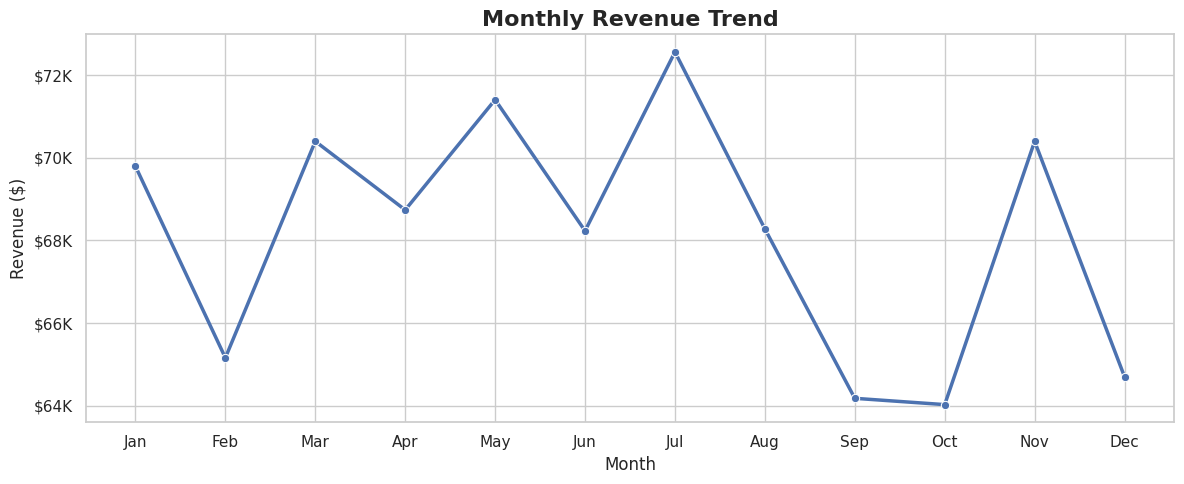

In [8]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker="o",
    linewidth=2.5
)

plt.title("Monthly Revenue Trend", fontsize=16, weight="bold")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x/1000:.0f}K")
)

plt.tight_layout()
plt.show()

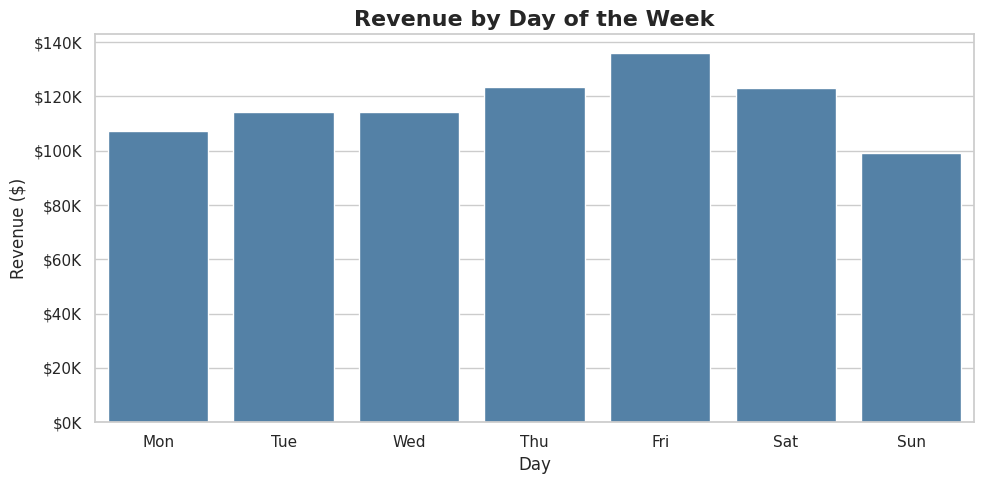

In [9]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekday_sales.index,
    y=weekday_sales.values,
    color="steelblue"
)

plt.title("Revenue by Day of the Week", fontsize=16, weight="bold")
plt.xlabel("Day")
plt.ylabel("Revenue ($)")
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x/1000:.0f}K")
)

plt.tight_layout()
plt.show()

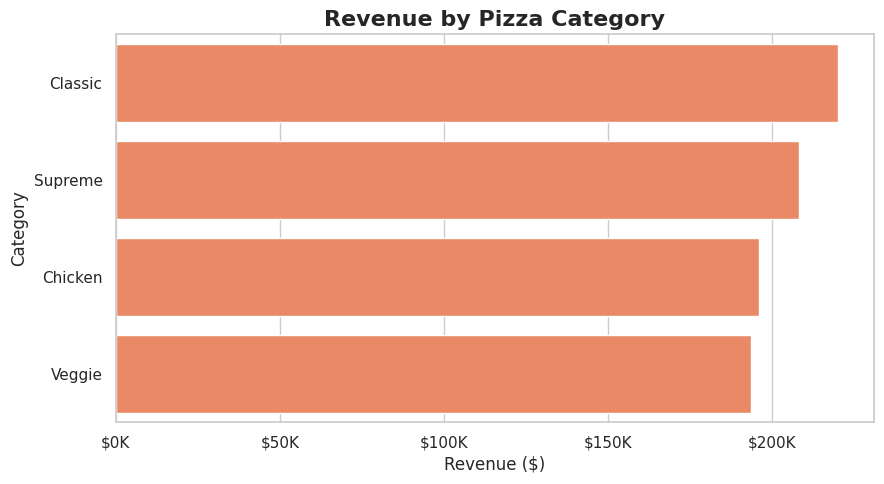

In [10]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=category_sales.values,
    y=category_sales.index,
    color="coral"
)

plt.title("Revenue by Pizza Category", fontsize=16, weight="bold")
plt.xlabel("Revenue ($)")
plt.ylabel("Category")
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x/1000:.0f}K")
)

plt.tight_layout()
plt.show()

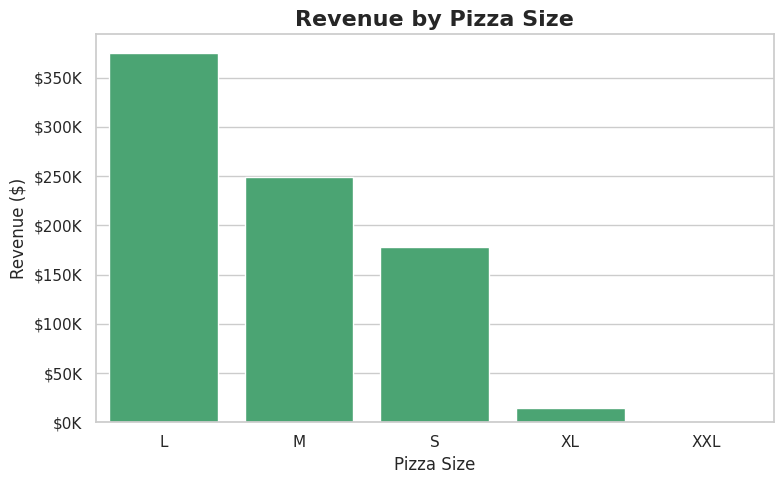

In [11]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=size_sales.index,
    y=size_sales.values,
    color="mediumseagreen"
)

plt.title("Revenue by Pizza Size", fontsize=16, weight="bold")
plt.xlabel("Pizza Size")
plt.ylabel("Revenue ($)")
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x/1000:.0f}K")
)

plt.tight_layout()
plt.show()

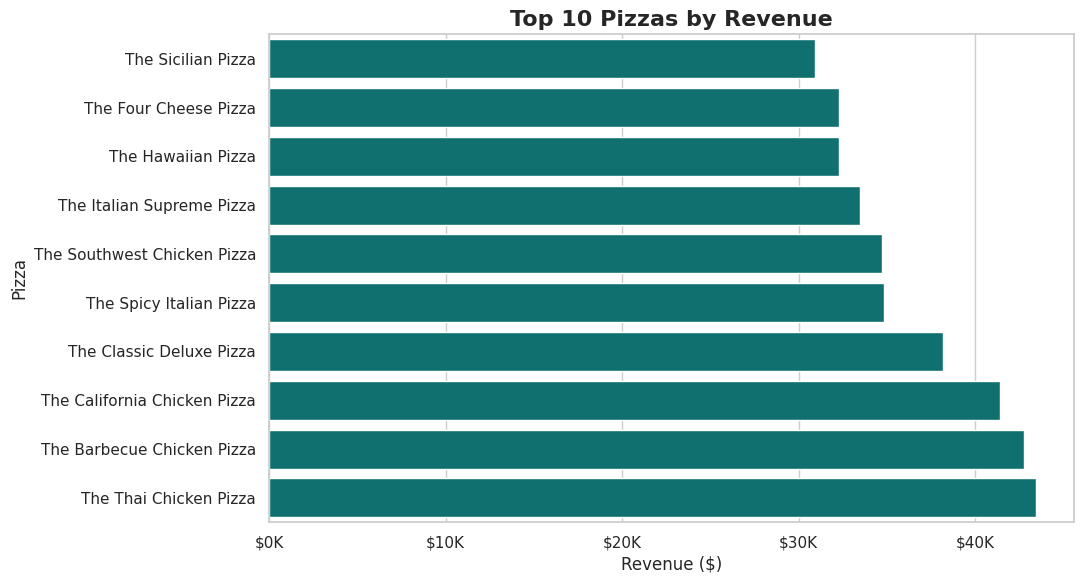

In [12]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=top_pizzas.values,
    y=top_pizzas.index,
    color="teal"
)

plt.title("Top 10 Pizzas by Revenue", fontsize=16, weight="bold")
plt.xlabel("Revenue ($)")
plt.ylabel("Pizza")
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x/1000:.0f}K")
)

plt.tight_layout()
plt.show()

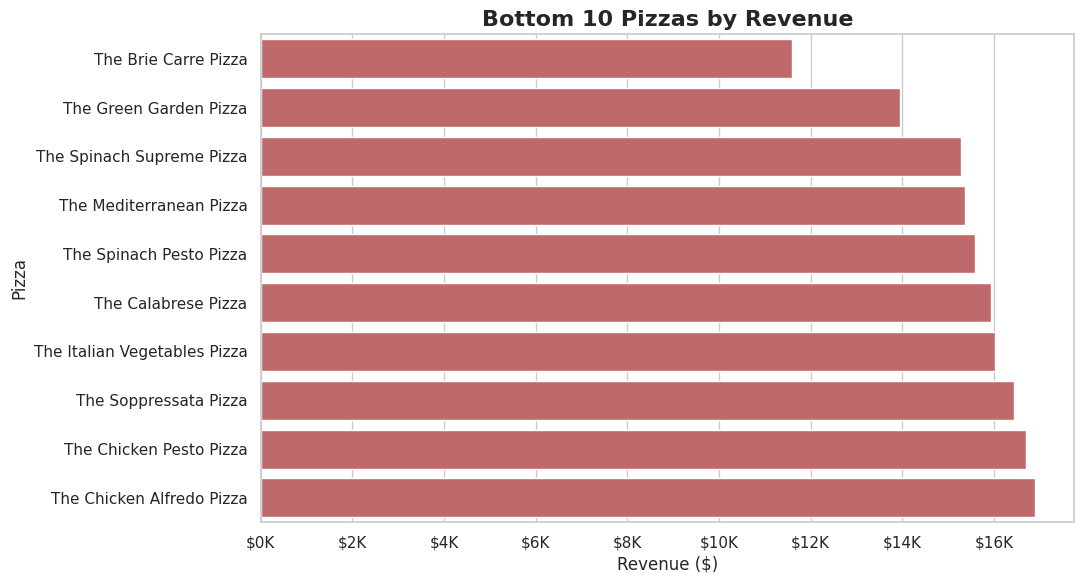

In [13]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=bottom_pizzas.values,
    y=bottom_pizzas.index,
    color="indianred"
)

plt.title("Bottom 10 Pizzas by Revenue", fontsize=16, weight="bold")
plt.xlabel("Revenue ($)")
plt.ylabel("Pizza")
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x/1000:.0f}K")
)

plt.tight_layout()
plt.show()

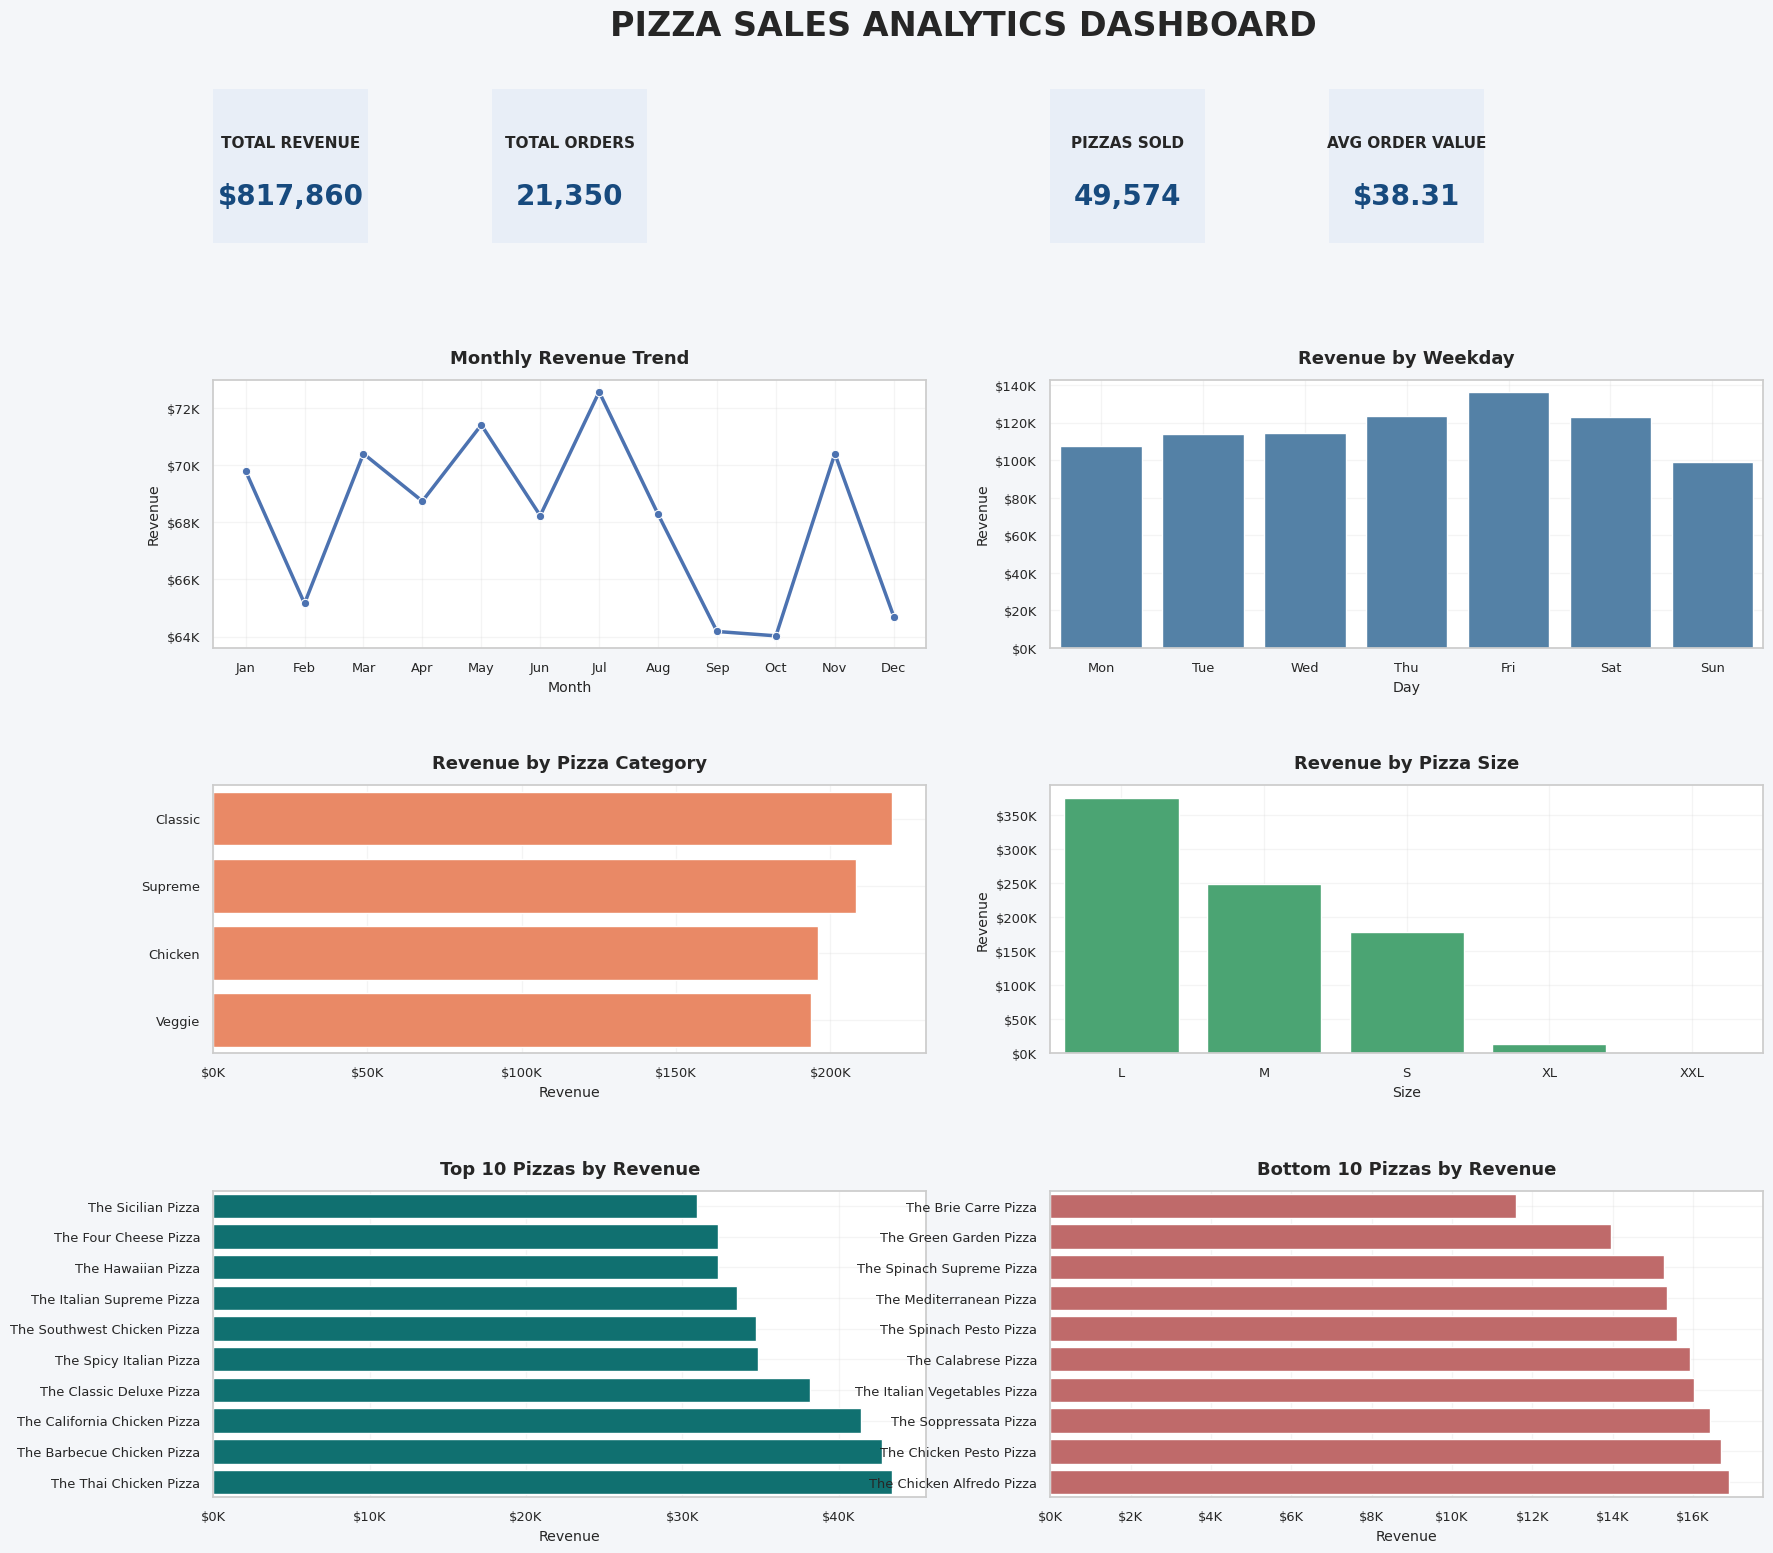

In [14]:
sns.set_theme(style="whitegrid", font_scale=0.85)

fig = plt.figure(figsize=(20, 16), facecolor="#F4F6F9")

gs = GridSpec(
    4, 6,
    figure=fig,
    height_ratios=[0.8, 1.4, 1.4, 1.6],
    hspace=0.55,
    wspace=0.8
)

fig.suptitle(
    "PIZZA SALES ANALYTICS DASHBOARD",
    fontsize=24,
    fontweight="bold",
    y=0.98
)

def format_axis(ax, axis="y"):
    formatter = FuncFormatter(lambda x, _: f"${x/1000:.0f}K")
    if axis == "y":
        ax.yaxis.set_major_formatter(formatter)
    else:
        ax.xaxis.set_major_formatter(formatter)

def style_axis(ax, title):
    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.set_facecolor("white")
    ax.grid(axis="x", alpha=0.2)
    ax.grid(axis="y", alpha=0.2)

kpis = [
    ("TOTAL REVENUE", f"${total_revenue:,.0f}"),
    ("TOTAL ORDERS", f"{total_orders:,}"),
    ("PIZZAS SOLD", f"{total_pizzas:,}"),
    ("AVG ORDER VALUE", f"${avg_order_value:,.2f}")
]

for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i * 3 // 2:i * 3 // 2 + 1])
    ax.set_facecolor("#E8EEF7")
    ax.text(
        0.5, 0.65, label,
        ha="center", va="center",
        fontsize=11, fontweight="bold",
        transform=ax.transAxes
    )
    ax.text(
        0.5, 0.30, value,
        ha="center", va="center",
        fontsize=20, fontweight="bold",
        color="#174A7E",
        transform=ax.transAxes
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

ax1 = fig.add_subplot(gs[1, :3])
sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker="o",
    linewidth=2.5,
    ax=ax1
)
style_axis(ax1, "Monthly Revenue Trend")
ax1.set_xlabel("Month")
ax1.set_ylabel("Revenue")
format_axis(ax1)

ax2 = fig.add_subplot(gs[1, 3:])
sns.barplot(
    x=weekday_sales.index,
    y=weekday_sales.values,
    color="steelblue",
    ax=ax2
)
style_axis(ax2, "Revenue by Weekday")
ax2.set_xlabel("Day")
ax2.set_ylabel("Revenue")
format_axis(ax2)

ax3 = fig.add_subplot(gs[2, :3])
sns.barplot(
    x=category_sales.values,
    y=category_sales.index,
    color="coral",
    ax=ax3
)
style_axis(ax3, "Revenue by Pizza Category")
ax3.set_xlabel("Revenue")
ax3.set_ylabel("")
format_axis(ax3, "x")

ax4 = fig.add_subplot(gs[2, 3:])
sns.barplot(
    x=size_sales.index,
    y=size_sales.values,
    color="mediumseagreen",
    ax=ax4
)
style_axis(ax4, "Revenue by Pizza Size")
ax4.set_xlabel("Size")
ax4.set_ylabel("Revenue")
format_axis(ax4)

ax5 = fig.add_subplot(gs[3, :3])
sns.barplot(
    x=top_pizzas.values,
    y=top_pizzas.index,
    color="teal",
    ax=ax5
)
style_axis(ax5, "Top 10 Pizzas by Revenue")
ax5.set_xlabel("Revenue")
ax5.set_ylabel("")
format_axis(ax5, "x")

ax6 = fig.add_subplot(gs[3, 3:])
sns.barplot(
    x=bottom_pizzas.values,
    y=bottom_pizzas.index,
    color="indianred",
    ax=ax6
)
style_axis(ax6, "Bottom 10 Pizzas by Revenue")
ax6.set_xlabel("Revenue")
ax6.set_ylabel("")
format_axis(ax6, "x")

plt.subplots_adjust(top=0.93, bottom=0.05)
plt.show()

In [15]:
fig.savefig(
    "pizza_sales_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)